# Classification: predicting credit default

## Introduction

How can you use information from a loan application to estimate the chance of default? This notebook revisits supervised learning through a worked **binary classification** example: a logistic regression (or *logit*) model fitted to synthetic credit data.

By the end, you can visualize a binary outcome, fit a model with scikit-learn, distinguish class predictions from probabilities, reconstruct probabilities from fitted parameters, and read a two-feature decision surface.

**Outline:** [Key Concepts](#key-concepts) · [Credit data and visualization](#credit-data-and-visualization) · [Logistic regression](#logistic-regression) · [Visualizing-logistic-regression](#visualizing-logistic-regression) · [Summary](#summary) · [Tasks](#tasks)

**Lecture connections:** Forecasting & Prediction, slides 4–5 (learning from labeled applications) and 29–30 (held-out data); Classification, slides 8, 14–25 and 29 (credit risk, logistic probabilities and class decisions).

We'll use **pandas** to explore the credit data, **NumPy** to reconstruct probabilities, and **Matplotlib** to visualize the results. **Scikit-learn** provides the data split and logistic regression model. The imports are collected below.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# Reuse one seed for every random operation in this notebook.
SEED = 67


## Key Concepts

### 1. Binary outcomes: turning information into decision support

Many practical decisions hinge on an outcome with two possibilities: an event happens or it does not. Examples include whether a customer defaults, a payment is fraudulent, or a patient is readmitted. A binary outcome model uses information available before the outcome to estimate the chance of one of these events. It helps people make decisions under uncertainty; it does not make the decision for them, and a predicted probability is not a guarantee of what will happen.

We code the event of interest as $y_i=1$ and its alternative as $y_i=0$. The model's goal is to estimate $P(y_i=1\mid\mathbf{x}_i)$, the probability of the event given the information $\mathbf{x}_i$ about case $i$.

### 2. Loan approval: an illustrative context

Imagine a lender deciding whether to approve a loan... 
![Classification lecture slide 8: bureau score and debt/income are application features; default is the later outcome.](../resources/2_credit_context.png)
An applicant's bureau score and debt-to-income ratio can help assess the risk of future default. In this notebook, the outcome we model is **default within the next 12 months**: $y_i=1$ means the borrower defaults, and $y_i=0$ means they do not. The two features are measured when the application is made, before that outcome is known.

That distinction matters: the model estimates default risk, not whether a historical application was approved. A lender can use the estimated risk as one input to an approval decision, together with its policies and the consequences of approving or declining. A risk estimate of 0.2, for example, means the model assigns a 20% probability of default—not that default is impossible for the other 80% of similar cases.

### 3. Logistic regression: a model for probabilities

For each case $i$, let $\mathbf{x}_i=(x_{i1},\ldots,x_{id})$ collect its $d$ features and let $\boldsymbol{\beta}=(\beta_1,\ldots,\beta_d)$ collect their coefficients. Logistic regression first forms a **linear predictor**:

$$\eta_i=\beta_0+\beta_1x_{i1}+\cdots+\beta_dx_{id}=\beta_0+\mathbf{x}_i^\top\boldsymbol{\beta}.$$

A linear predictor can take any value, so it cannot itself be a probability. The logistic function maps it to a value strictly between zero and one; when $\eta_i=0$, the estimated probability is $0.5$, and larger values of $\eta_i$ give larger probabilities:

$$P(y_i=1\mid\mathbf{x}_i)=p_i=\frac{1}{1+\exp(-\eta_i)}.$$

Equivalently, the **log-odds** of the event are linear in the features. Holding the other features fixed, increasing $x_{ij}$ by one unit changes the log-odds by $\beta_j$:

$$\log\!\left(\frac{p_i}{1-p_i}\right)=\eta_i.$$

The coefficients are learned from labeled examples. In the loan example, $d=2$, $x_{i1}$ can be bureau score, and $x_{i2}$ the debt-to-income ratio (in percent). Once the coefficients have been estimated from training data, the predicted probability of default is

$$\widehat{p}_i=\frac{1}{1+\exp\!\left[-\left(\widehat{\beta}_0+\widehat{\beta}_1x_{i1}+\widehat{\beta}_2x_{i2}\right)\right]}.$$

A lender may then compare this probability with a chosen threshold $\tau$ to produce a class prediction:

$$\widehat{y}_i(\tau)=\mathbb{I}\{\widehat{p}_i\geq \tau\}.$$

The threshold is a decision rule, not part of the probability model; its choice can reflect the costs of different mistakes or other lending constraints. This is why it is useful to keep the estimated probability and the eventual approve-or-decline decision distinct.

### 4. The same method applies elsewhere

The loan example makes the ideas concrete, but neither the logistic function nor the modeling steps are specific to finance. The same approach can estimate the probability of a fraudulent transaction, customer churn, equipment failure, or another clearly defined binary outcome. Choose what counts as $y=1$, use features that:

- are available at prediction time, and
- supposedly influence the probability of the outcome,

and interpret the resulting probability estimate in that context.

## Credit data and visualization

### Load the applications


For demonstration, we use synthetic dataset and consider just two features:

| Column | Meaning and units |
|---|---|
| `bureau_score` | Stylized bureau score on a 300–850 point scale; higher means stronger creditworthiness |
| `debt_income` | Monthly debt payments / gross monthly income × 100; 35 represents a debt/income ratio of 35% |
| `default` | 1 = default within 12 months; 0 = no default within 12 months |

These are fictional borrowers. The features are recorded before the outcome, so they could be available when a new application arrives and facilitate predicting repayment.

The code loads the supplied CSV from `data/`, using a path relative to this notebook’s folder.

In [2]:
credit = pd.read_csv('../data/credit_data.csv')
print(f"Shape of the dataset: {credit.shape}")
credit.head()


Shape of the dataset: (1200, 3)


,bureau_score,debt_income,default
0,686,14.8,0
1,572,25.7,1
2,724,37.5,0
3,740,30.7,0
4,494,23.5,1


In [3]:
credit.describe().round(2)

,bureau_score,debt_income,default
count,1200.00,1200.00,1200.00
mean,657.79,31.30,0.33
std,82.91,12.93,0.47
min,350.00,5.00,0.00
25%,602.00,22.58,0.00
50%,660.00,31.80,0.00
75%,712.00,39.90,1.00
max,850.00,65.00,1.00


Selecting the feature columns with a list inside `[...]` produces a two-column **DataFrame**. Selecting the target with one column name produces a one-dimensional **Series**. Both retain the same row index, keeping each application aligned with its outcome.

The next cell reserves 25% of applications for testing before fitting. `stratify=y` approximately preserves the class proportions, and `random_state` makes the split reproducible. We use the training applications for exploratory plots and keep the test cases for later predictions.

In [4]:
feature_names = ['bureau_score', 'debt_income']
X = credit[feature_names] # data frame with the features
y = credit['default'] # target variable 

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=SEED
)
print(f'Training applications: {len(X_train)}; test applications: {len(X_test)}')
print(f'Training default share: {y_train.mean():.1%}')

Training applications: 900; test applications: 300
Training default share: 33.1%


### Binary target versus one feature

The first scatter plot places bureau score on the horizontal axis and observed default on the vertical axis. `alpha` makes points translucent so overlapping observations are easier to see. Each point retains its observed binary target value.

Before running the cell, anticipate the vertical positions at which points can appear.

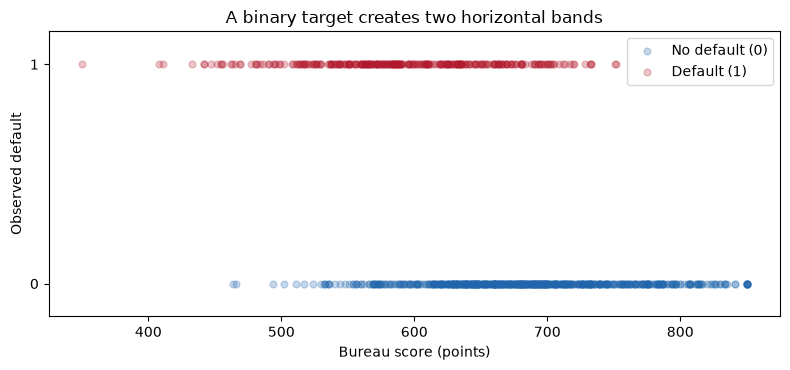

In [5]:
# Create a scatter plot of the default indicator against the bureau score, colored by default status
class_colors = ['#2166ac', '#b2182b']
class_labels = ['No default (0)', 'Default (1)']
fig, ax = plt.subplots(figsize=(8, 3.8))
for label in [0, 1]:
    selected = y_train == label
    ax.scatter(X_train.loc[selected, 'bureau_score'], y_train.loc[selected],
               color=class_colors[label], alpha=0.25, s=24, label=class_labels[label])
ax.set(xlabel='Bureau score (points)', ylabel='Observed default',
       yticks=[0, 1], ylim=(-0.15, 1.15), title='A binary target creates two horizontal bands')
ax.legend()
plt.tight_layout()
plt.show()

The binary target produces two horizontal bands. Compare the score ranges within the bands: defaulting borrowers tend to have lower scores, with substantial overlap between the classes.

Task 1 returns to this plot with `debt_income` on the horizontal axis.

### Two features, colored by outcome

The next plot uses both axes for features and shows the outcome through color. This is the feature-space view from the lecture. Look for regions where defaults are more common.

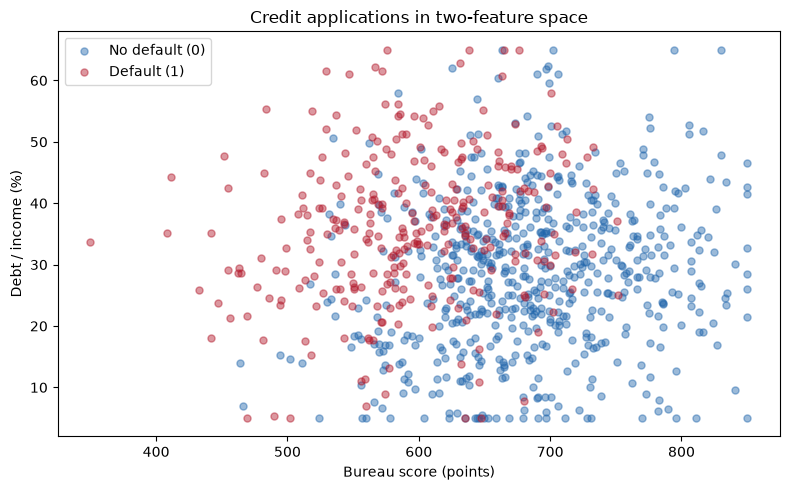

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
for label in [0, 1]:
    selected = y_train == label
    ax.scatter(X_train.loc[selected, 'bureau_score'],
               X_train.loc[selected, 'debt_income'],
               color=class_colors[label], alpha=0.45, s=26, label=class_labels[label])
ax.set(xlabel='Bureau score (points)', ylabel='Debt / income (%)',
       title='Credit applications in two-feature space')
ax.legend()
plt.tight_layout()
plt.show()

<p style="color: red;"><strong>Disclaimer: Please note that the following interpretation assumes you executed the original code. Changes can invalidate our interpretation.</strong></p>

Lower bureau scores and higher debt/income tend to coincide with defaults in these data. The mixed colors also show why a probabilistic model is appropriate. These patterns describe predictive associations. A causal interpretation requires additional evidence.

## Logistic regression

### Fit the model

**Scikit-learn** estimators share a common interface. In the code below, model creation is followed by `.fit(X_train, y_train)`, which estimates its parameters. Prediction methods then apply the fitted model to new feature rows. Logistic regression estimates its parameters using a probability-based objective.

We use the `newton-cholesky` solver, which works well for this small, two-feature problem and lets us keep the original feature units. Other settings, including scikit-learn's default regularization, stay at their defaults.

In [7]:
model = LogisticRegression(solver='newton-cholesky')
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'newton-cholesky'
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. so

Attributes ending in `_` become available after fitting. `intercept_` contains the fitted intercept; `coef_` contains the coefficients in the order of the training feature columns. `classes_` tells you the order of class labels used by the prediction methods.

In [8]:
parameters = pd.Series(
    [model.intercept_[0], *model.coef_[0]],
    index=['intercept', *feature_names],
    name='Estimated parameter'
)
print(parameters.round(5))
print('Class order:', model.classes_)

intercept       10.49185
bureau_score    -0.02111
debt_income      0.07069
Name: Estimated parameter, dtype: float64
Class order: [0 1]


### `.predict` versus `.predict_proba`

The example selects five held-out applications using `.iloc[:5]` (the first five rows by position). `.predict` returns one class label per row. `.predict_proba` returns one probability per class: here column 0 is no default, and column 1 is default, as confirmed by `classes_`.

These applications retain the feature names, order and units used in training.

In [10]:
applications = X_test.iloc[:5]
# Note the differences in the outputs of the two methods:
#  `predict` returns the predicted class, while `predict_proba` 
# returns the predicted probabilities for each class.
class_predictions = model.predict(applications)
class_probabilities = model.predict_proba(applications)

prediction_table = applications.copy()
prediction_table['P(no default)'] = class_probabilities[:, 0]
prediction_table['P(default)'] = class_probabilities[:, 1]
prediction_table['predicted_class'] = class_predictions
prediction_table['observed_default'] = y_test.loc[applications.index]
prediction_table.round(3)

,bureau_score,debt_income,P(no default),P(default),predicted_class,observed_default
239,615,46.6,0.309,0.691,1,1
179,684,51.2,0.581,0.419,0,0
276,595,59.2,0.108,0.892,1,1
616,721,40.6,0.865,0.135,0,0
1193,724,36.0,0.904,0.096,0,0


Each row's two probabilities sum to one. The class label discards how close the default probability is to the **decision threshold**. Note that you never selected the threshold, denoated by $\tau$ in the formal summary of the logistic regression model. This is a characteristics of the `.predict()` function. It assumes a **standard** threshold and does not allow you to overwrite it. 

Looking at the table, no doubt you can guess what standard threshold the `.predict()` method uses, right? 
Also inspect the probabilities to see the model's degree of confidence. Assume you would want to change the threshold. As said, `.predict()` does not provide a function argument or other means to do so. How could you still change it?

### Compute probabilities from the estimated parameters

The next cell reconstructs the same five predictions from the fitted equation: it multiplies each feature by its estimated coefficient, adds the intercept, and applies the logistic function. This is the numerical equivalent of the formula in Key Concepts.

The first row below prints every term so you can check the calculation with a calculator. The remaining rows use exactly the same calculation.

In [12]:
intercept = model.intercept_[0]
bureau_coefficient, debt_coefficient = model.coef_[0]
# Compute the linear predictor and the predicted probability by hand 
linear_predictor = (
    intercept
    + bureau_coefficient * applications['bureau_score']
    + debt_coefficient * applications['debt_income']
)
manual_probability = 1 / (1 + np.exp(-linear_predictor))

first = applications.iloc[0]
print(f'First application: eta = {intercept:.6f}'
      f' + ({bureau_coefficient:.6f}) * {first["bureau_score"]:.0f}'
      f' + ({debt_coefficient:.6f}) * {first["debt_income"]:.1f}'
      f' = {linear_predictor.iloc[0]:.6f}')
print(f'P(default) = 1 / (1 + exp(-eta)) = {manual_probability.iloc[0]:.6f}')
pd.DataFrame({
    'linear_predictor': linear_predictor,
    'manual_probability': manual_probability,
    'sklearn_probability': class_probabilities[:, 1]
}).round(6)

First application: eta = 10.491850 + (-0.021110) * 615 + (0.070695) * 46.6 = 0.803507
P(default) = 1 / (1 + exp(-eta)) = 0.690724


,linear_predictor,manual_probability,sklearn_probability
239,0.803507,0.690724,0.690724
179,-0.327895,0.418753,0.418753
276,2.116466,0.892493,0.892493
616,-1.858337,0.134897,0.134897
1193,-2.246864,0.095620,0.095620


The manually reconstructed probabilities agree with scikit-learn's output. The calculation uses the full fitted parameters; rounding them first can create discrepancies.

### From probabilities to classes: the fixed threshold
![Classification lecture slide 25: a horizontal cut-off converts a logistic probability curve into class decisions.](../resources/2_classification_threshold.png)
**Read the target carefully:** the slide codes *repayment* as 1, so its curve shows repayment probability. Here we code **default as 1**, so our probabilities have the opposite meaning.

For binary logistic regression, `.predict` chooses the class with the larger probability. With classes `[0, 1]`, this corresponds to default when its probability **exceeds 0.5**. At an exact tie, scikit-learn chooses class 0. Our mathematical rule uses `>=`; the difference matters only at exactly 0.5.

The cell below reconstructs `.predict` using its threshold convention. The software default is 0.5. A business threshold depends on the consequences of decisions.

In [13]:
threshold_classes = (class_probabilities[:, 1] > 0.5).astype(int)
pd.DataFrame({
    'P(default)': class_probabilities[:, 1],
    'predict': class_predictions,
    'threshold_0.5': threshold_classes
}, index=applications.index).round(3)

,P(default),predict,threshold_0.5
239,0.691,1,1
179,0.419,0,0
276,0.892,1,1
616,0.135,0,0
1193,0.096,0,0


As a brief held-out check, `.score` reports classification accuracy: the fraction of test labels predicted correctly at the default threshold. Compare it with always predicting the majority class identified from training data. These accuracy values summarize class decisions. Economic value and probability quality require their own assessments.

In [14]:
majority_class = y_train.mode().iloc[0]
print(f'Test accuracy: {model.score(X_test, y_test):.1%}')
print(f'Majority-class test accuracy: {(y_test == majority_class).mean():.1%}')

Test accuracy: 75.0%
Majority-class test accuracy: 66.7%


## Visualizing logistic regression

The final worked example overlays fitted probabilities on the two-feature scatter plot. `np.meshgrid` creates a rectangular grid of bureau scores and debt/income values. The code flattens the grid coordinates into a DataFrame, predicts at every grid point, and reshapes the probabilities back into a rectangle for plotting.

The background represents **estimated default probability**; the points show **observed outcomes on held-out applications**. The black line marks probability 0.5. It separates the class predictions while the background retains their probability information.

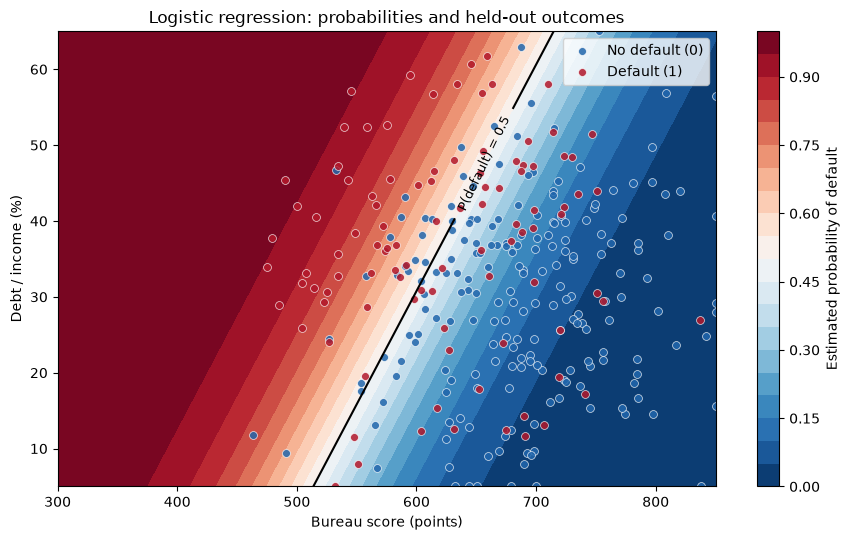

In [15]:
bureau_values = np.linspace(300, 850, 160)
debt_values = np.linspace(5, 65, 160)
bureau_grid, debt_grid = np.meshgrid(bureau_values, debt_values)
grid = pd.DataFrame({
    'bureau_score': bureau_grid.ravel(),
    'debt_income': debt_grid.ravel()
})
grid_probability = model.predict_proba(grid)[:, 1].reshape(bureau_grid.shape)

fig, ax = plt.subplots(figsize=(9, 5.5))
surface = ax.contourf(bureau_grid, debt_grid, grid_probability,
                      levels=np.linspace(0, 1, 21), cmap='RdBu_r', vmin=0, vmax=1)
fig.colorbar(surface, ax=ax, label='Estimated probability of default')
boundary = ax.contour(bureau_grid, debt_grid, grid_probability,
                      levels=[0.5], colors='black', linewidths=1.5)
ax.clabel(boundary, fmt={0.5: 'P(default) = 0.5'}, fontsize=9)
for label in [0, 1]:
    selected = y_test == label
    ax.scatter(X_test.loc[selected, 'bureau_score'], X_test.loc[selected, 'debt_income'],
               color=class_colors[label], edgecolor='white', linewidth=0.5,
               s=32, alpha=0.85, label=class_labels[label])
ax.set(xlabel='Bureau score (points)', ylabel='Debt / income (%)',
       title='Logistic regression: probabilities and held-out outcomes')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

<p style="color: red;"><strong>Disclaimer: Please note that the following interpretation assumes you executed the original code. Changes can invalidate our interpretation.</strong></p>

Follow the background from high bureau scores and low debt/income toward low scores and high debt/income: predicted default risk rises. Defaults can still occur in lower-risk regions, and non-defaults in higher-risk regions.

Why is the 0.5 boundary straight even though the logistic function is curved? Probability 0.5 corresponds to a linear predictor of zero. With two features and no interaction terms, that equation describes a straight line. The full rectangular background includes sparse combinations near the corners; predictions in those regions have less support from the data.

## Summary

- A binary scatter plot puts observations on two bands; a feature-space scatter plot uses color to show the target.
- `.fit(X_train, y_train)` estimates parameters; predictions depend on retaining the training feature order and units.
- `.predict_proba(X)[:, 1]` gives default probabilities here because `model.classes_` is `[0, 1]`; `.predict(X)` gives labels using the default decision threshold.
- Applying `1 / (1 + np.exp(-linear_predictor))` to the intercept plus weighted features reconstructs a fitted probability.
- A probability surface shows gradual changes in risk; its decision boundary shows where class predictions switch.

Here's a quick reference for the new Python tools introduced in this notebook:

| Python pattern | What it helps you do |
|---|---|
| `.iloc` | Select borrowers by row position |
| `LogisticRegression` | Fit a binary probability model |
| `model.classes_`, `model.predict_proba(X)` | Identify class order and obtain class probabilities |
| `np.exp` | Apply the logistic function to a linear predictor |
| `model.score(X_test, y_test)` | Calculate classification accuracy |
| `np.linspace`, `np.meshgrid`, `.ravel()`, `.reshape()` | Build and arrange a grid of feature combinations |
| `ax.scatter`, `ax.contourf`, `ax.contour`, `fig.colorbar` | Plot outcomes, probability surfaces and decision boundaries |

## Tasks

Use the working cells below. Each task builds on a pattern you have already used. Write a short interpretation alongside your code.

### Task 1: Change the single-feature view

Plot observed default against **debt/income** for the training applications. Label the horizontal axis in percent and retain the binary vertical axis. Where do defaults appear more frequently, and what does the overlap tell you?

*Hint:* adapt the first scatter plot and keep the target unchanged.

In [ ]:
# YOUR CODE: plot default against debt/income.

### Task 2: Inspect an application

Choose a different row from `X_test`. Reconstruct its default probability from the fitted parameters, compare it with `.predict_proba`, and report its `.predict` label. Explain why the probability and label answer different questions.

*Hint:* `X_test.iloc[[10]]` keeps a one-row DataFrame suitable for scikit-learn.

In [ ]:
# YOUR CODE: reconstruct and compare one held-out prediction.

### Task 3: Read the fitted map

Add contours at probabilities 0.25 and 0.75 to the final plot, using the already computed grid probabilities. Label the contours and identify the region between them. What information does this view retain that a plot of predicted classes alone would hide?

*Hint:* use `ax.contour(..., levels=[0.25, 0.75])` while rebuilding the figure.

In [ ]:
# YOUR CODE: extend the probability-surface visualization.